In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [2]:
# Bin errors by time
n_bins = 100
t_bins = np.linspace(0, 1, n_bins + 1)
t_centers = 0.5 * (t_bins[:-1] + t_bins[1:])

def binned_mean_error(t_vals, errors, bins):
    bin_idx = np.clip(np.digitize(t_vals, bins) - 1, 0, len(bins) - 2)
    means = np.array([errors[bin_idx == i].mean() if (bin_idx == i).any() else np.nan
                      for i in range(len(bins) - 1)])
    return means

In [3]:
models = ['base', 'ads', 'ads_time', 'cosine', 'x0_cond']

In [4]:
# Load additional parquet files
datasets = {
    'base': pd.read_parquet('base_u.parquet'),
    'ads': pd.read_parquet('ads_u.parquet'),
    'ads_time': pd.read_parquet('ads_time_u.parquet'),
    'cosine': pd.read_parquet('cosine_u.parquet'),
    'x0_cond': pd.read_parquet('x0_cond_u.parquet')
}

# Process each dataset: compute error, drift, masks, and binned means
results = {}
for name, data in datasets.items():
    t_vals = data['t'].values
    f_vals = data[['f_x', 'f_y', 'f_z']].values
    u_vals = data[['u_x', 'u_y', 'u_z']].values
    tags_vals = data['tags'].values

    err = abs(f_vals - u_vals).mean(axis=1)
    dft = (f_vals - u_vals).mean(axis=1)

    is_ads = (tags_vals == 2)
    is_cat = (tags_vals == 1)

    cat_err = binned_mean_error(t_vals[is_cat], err[is_cat], t_bins)
    ads_err = binned_mean_error(t_vals[is_ads], err[is_ads], t_bins)
    cat_dft = binned_mean_error(t_vals[is_cat], dft[is_cat], t_bins)
    ads_dft = binned_mean_error(t_vals[is_ads], dft[is_ads], t_bins)

    results[name] = {
        'cat_error': cat_err,
        'ads_error': ads_err,
        'cat_drift': cat_dft,
        'ads_drift': ads_dft,
    }

    print(f'--- {name} ---')
    print(f'  Catalyst MAE:   {err[is_cat].mean():.4f}')
    print(f'  Catalyst MAXE:   {err[is_cat].max():.4f}')
    print(f'  Adsorbate MAE:  {err[is_ads].mean():.4f}')
    print(f'  Adsorbate MAXE:  {err[is_ads].max():.4f}')


--- base ---
  Catalyst MAE:   0.0262
  Catalyst MAXE:   7.5110
  Adsorbate MAE:  0.1373
  Adsorbate MAXE:  10.6545
--- ads ---
  Catalyst MAE:   0.0416
  Catalyst MAXE:   2.9793
  Adsorbate MAE:  0.1511
  Adsorbate MAXE:  9.3630
--- ads_time ---
  Catalyst MAE:   0.0467
  Catalyst MAXE:   3.2031
  Adsorbate MAE:  0.1535
  Adsorbate MAXE:  9.3548
--- cosine ---
  Catalyst MAE:   0.0251
  Catalyst MAXE:   12.0885
  Adsorbate MAE:  0.1369
  Adsorbate MAXE:  14.2657
--- x0_cond ---
  Catalyst MAE:   0.0164
  Catalyst MAXE:   6.4153
  Adsorbate MAE:  0.0674
  Adsorbate MAXE:  6.4022


In [5]:
colors = {'base': 'steelblue', 'ads': 'coral', 'ads_time': 'seagreen', 'cosine': 'firebrick', 'x0_cond': 'k'}
markers = {'base': 'o', 'ads': 's', 'ads_time': '^', 'cosine': 'd', 'x0_cond': 'x'}

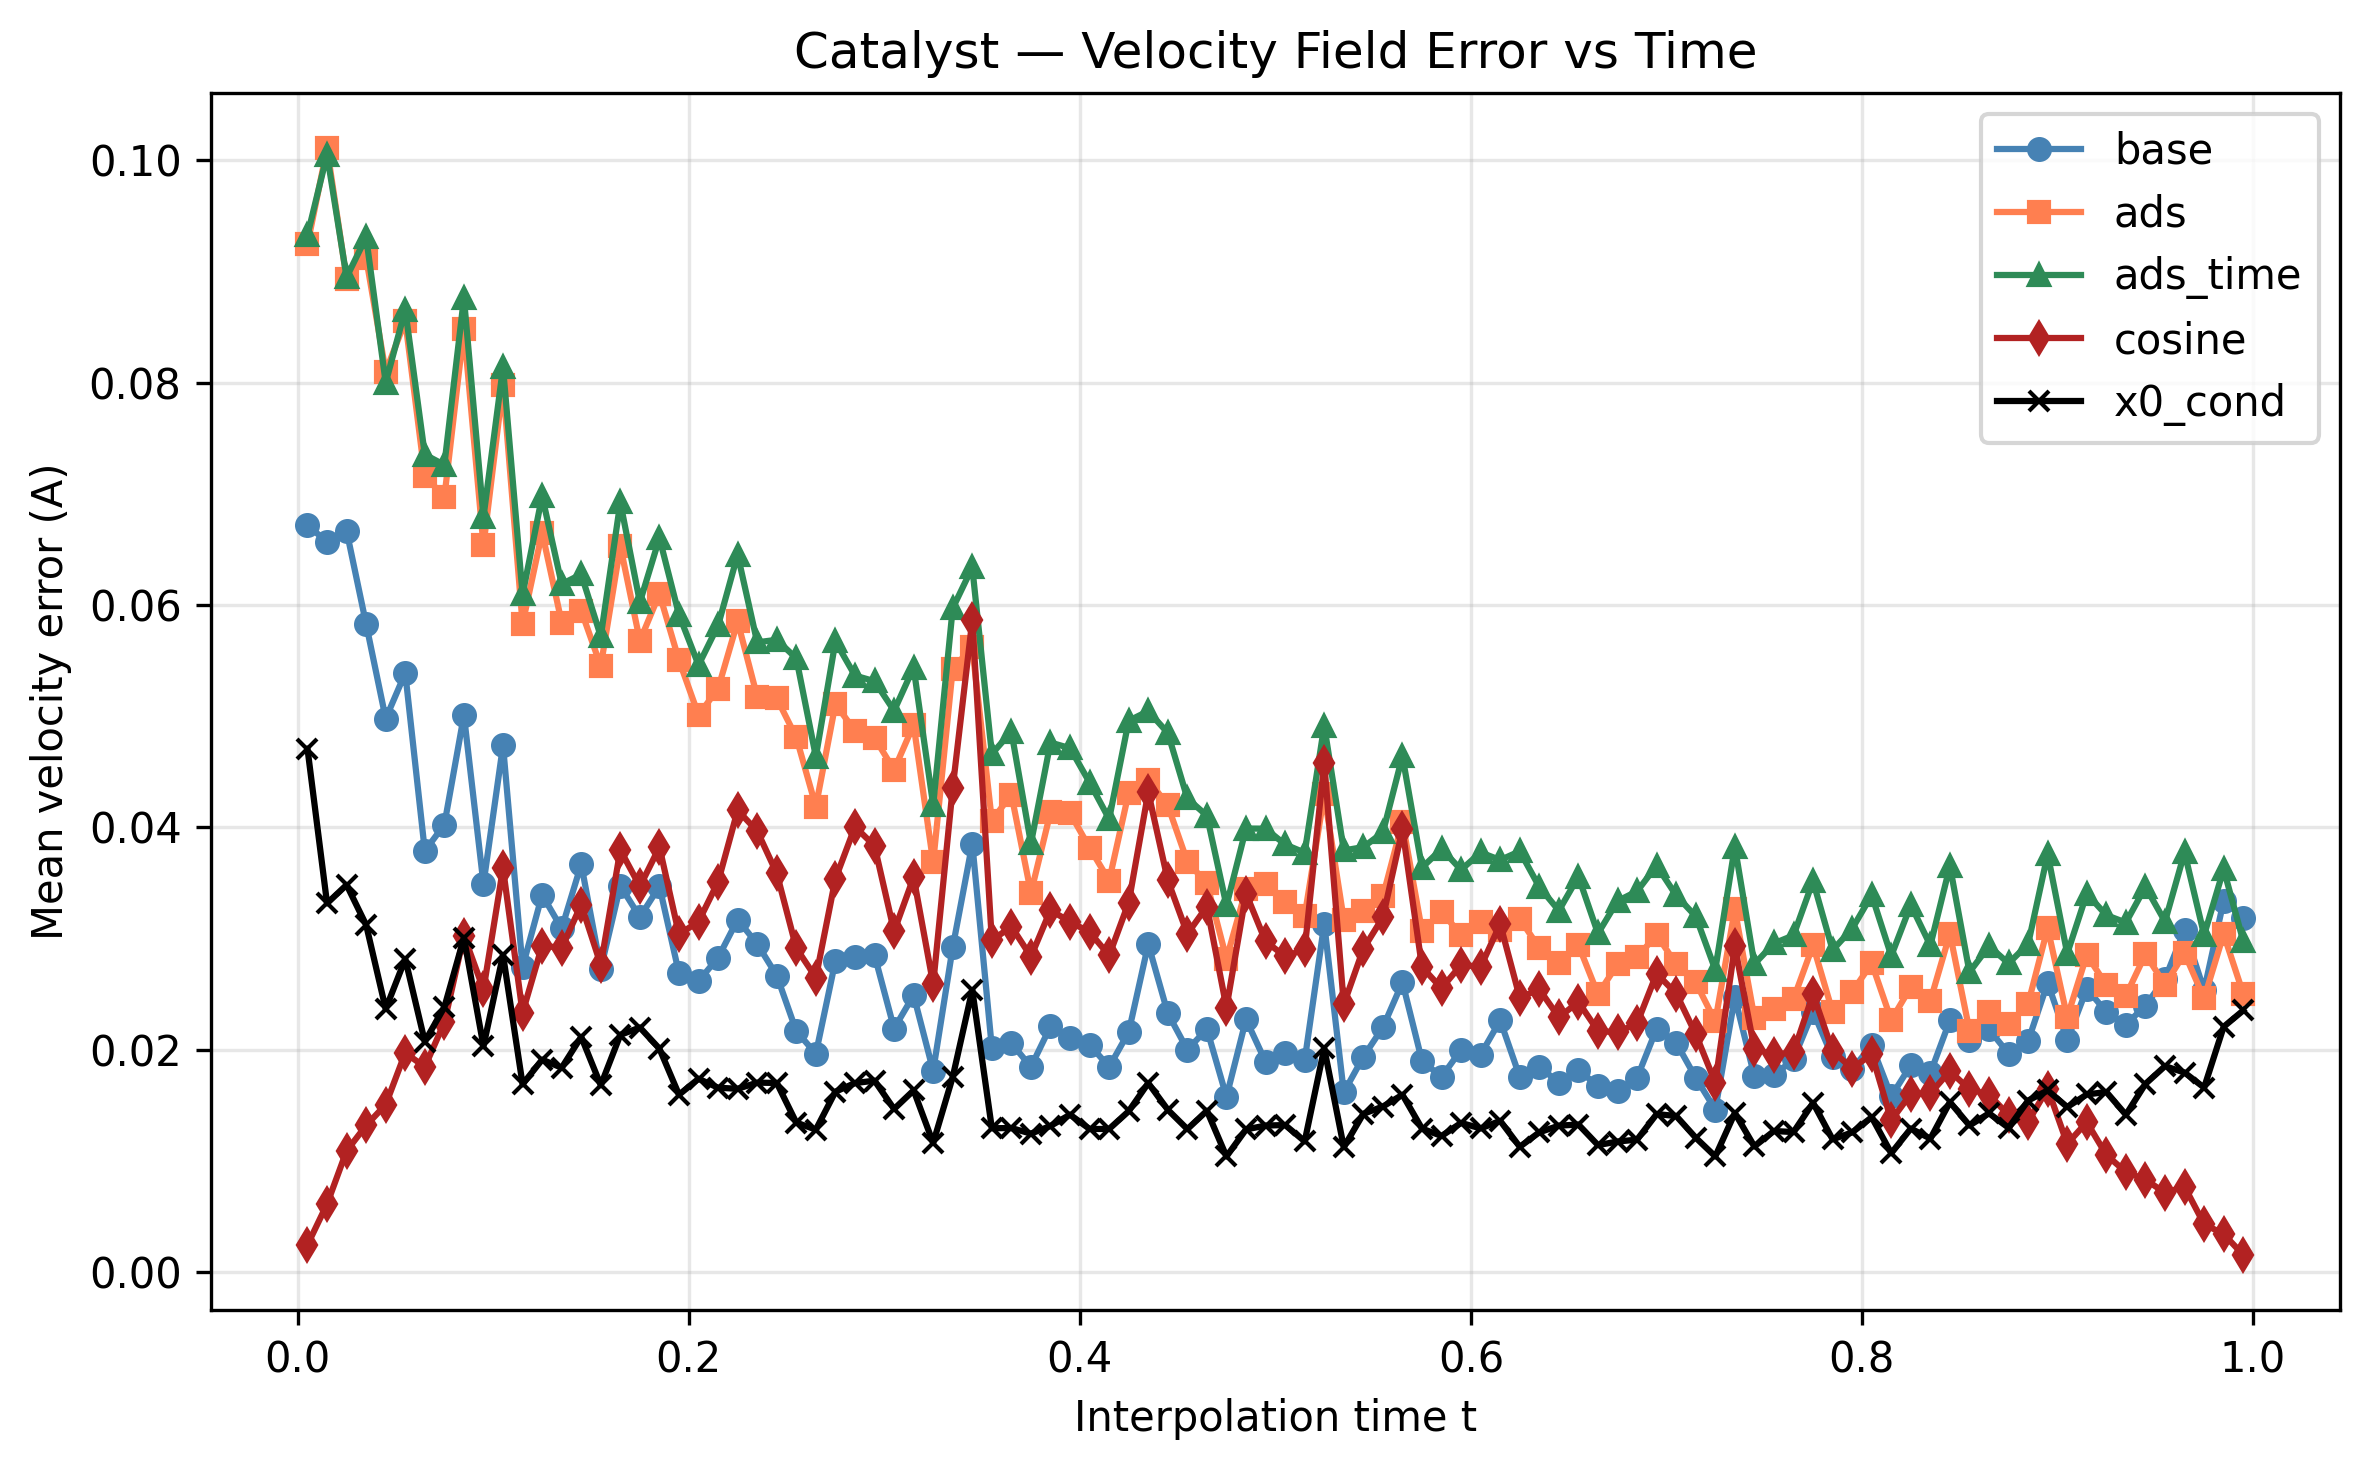

In [6]:
# Catalyst L2 Error — all datasets
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
for name in models:
    ax.plot(t_centers, results[name]['cat_error'],
            f'{markers[name]}-', label=name, color=colors[name], markersize=5)
ax.set_xlabel('Interpolation time t')
ax.set_ylabel('Mean velocity error (A)')
ax.set_title('Catalyst — Velocity Field Error vs Time')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


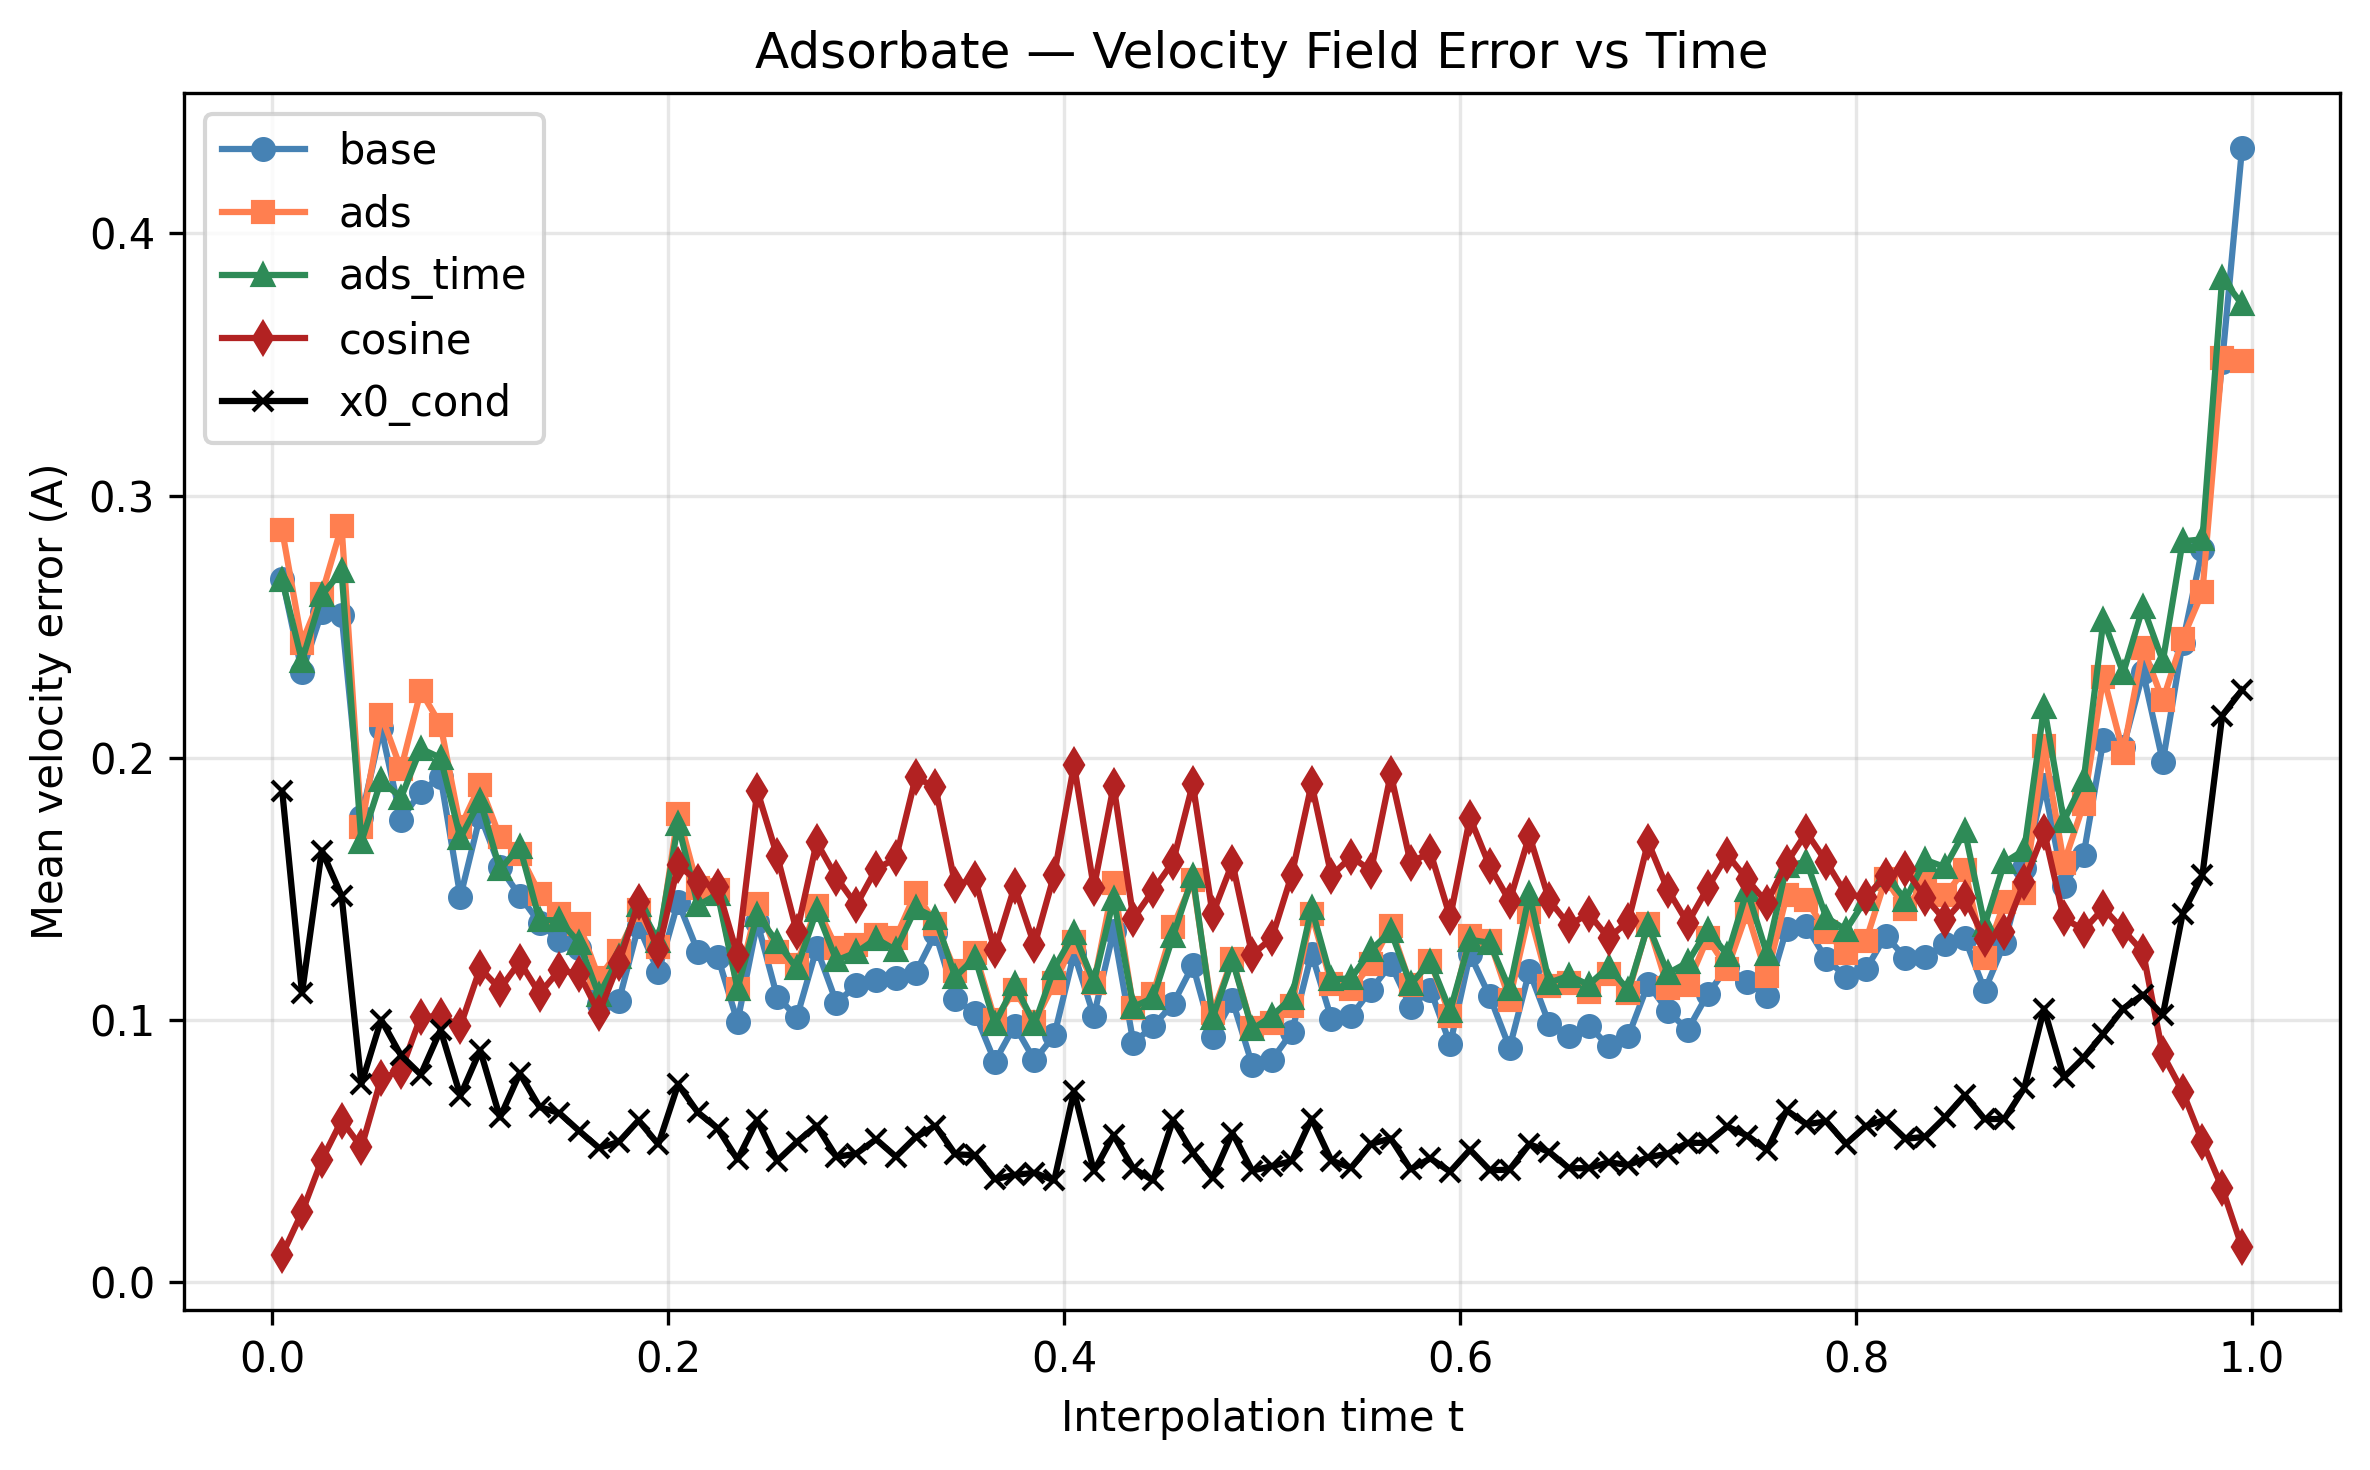

In [ ]:
# Adsorbate L2 Error — all datasets
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
for name in models:
    ax.plot(t_centers, results[name]['ads_error'],
            f'{markers[name]}-', label=name, color=colors[name], markersize=5)
ax.set_xlabel('Interpolation time t')
ax.set_ylabel('Mean velocity error (A)')
ax.set_title('Adsorbate — Velocity Field Error vs Time')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

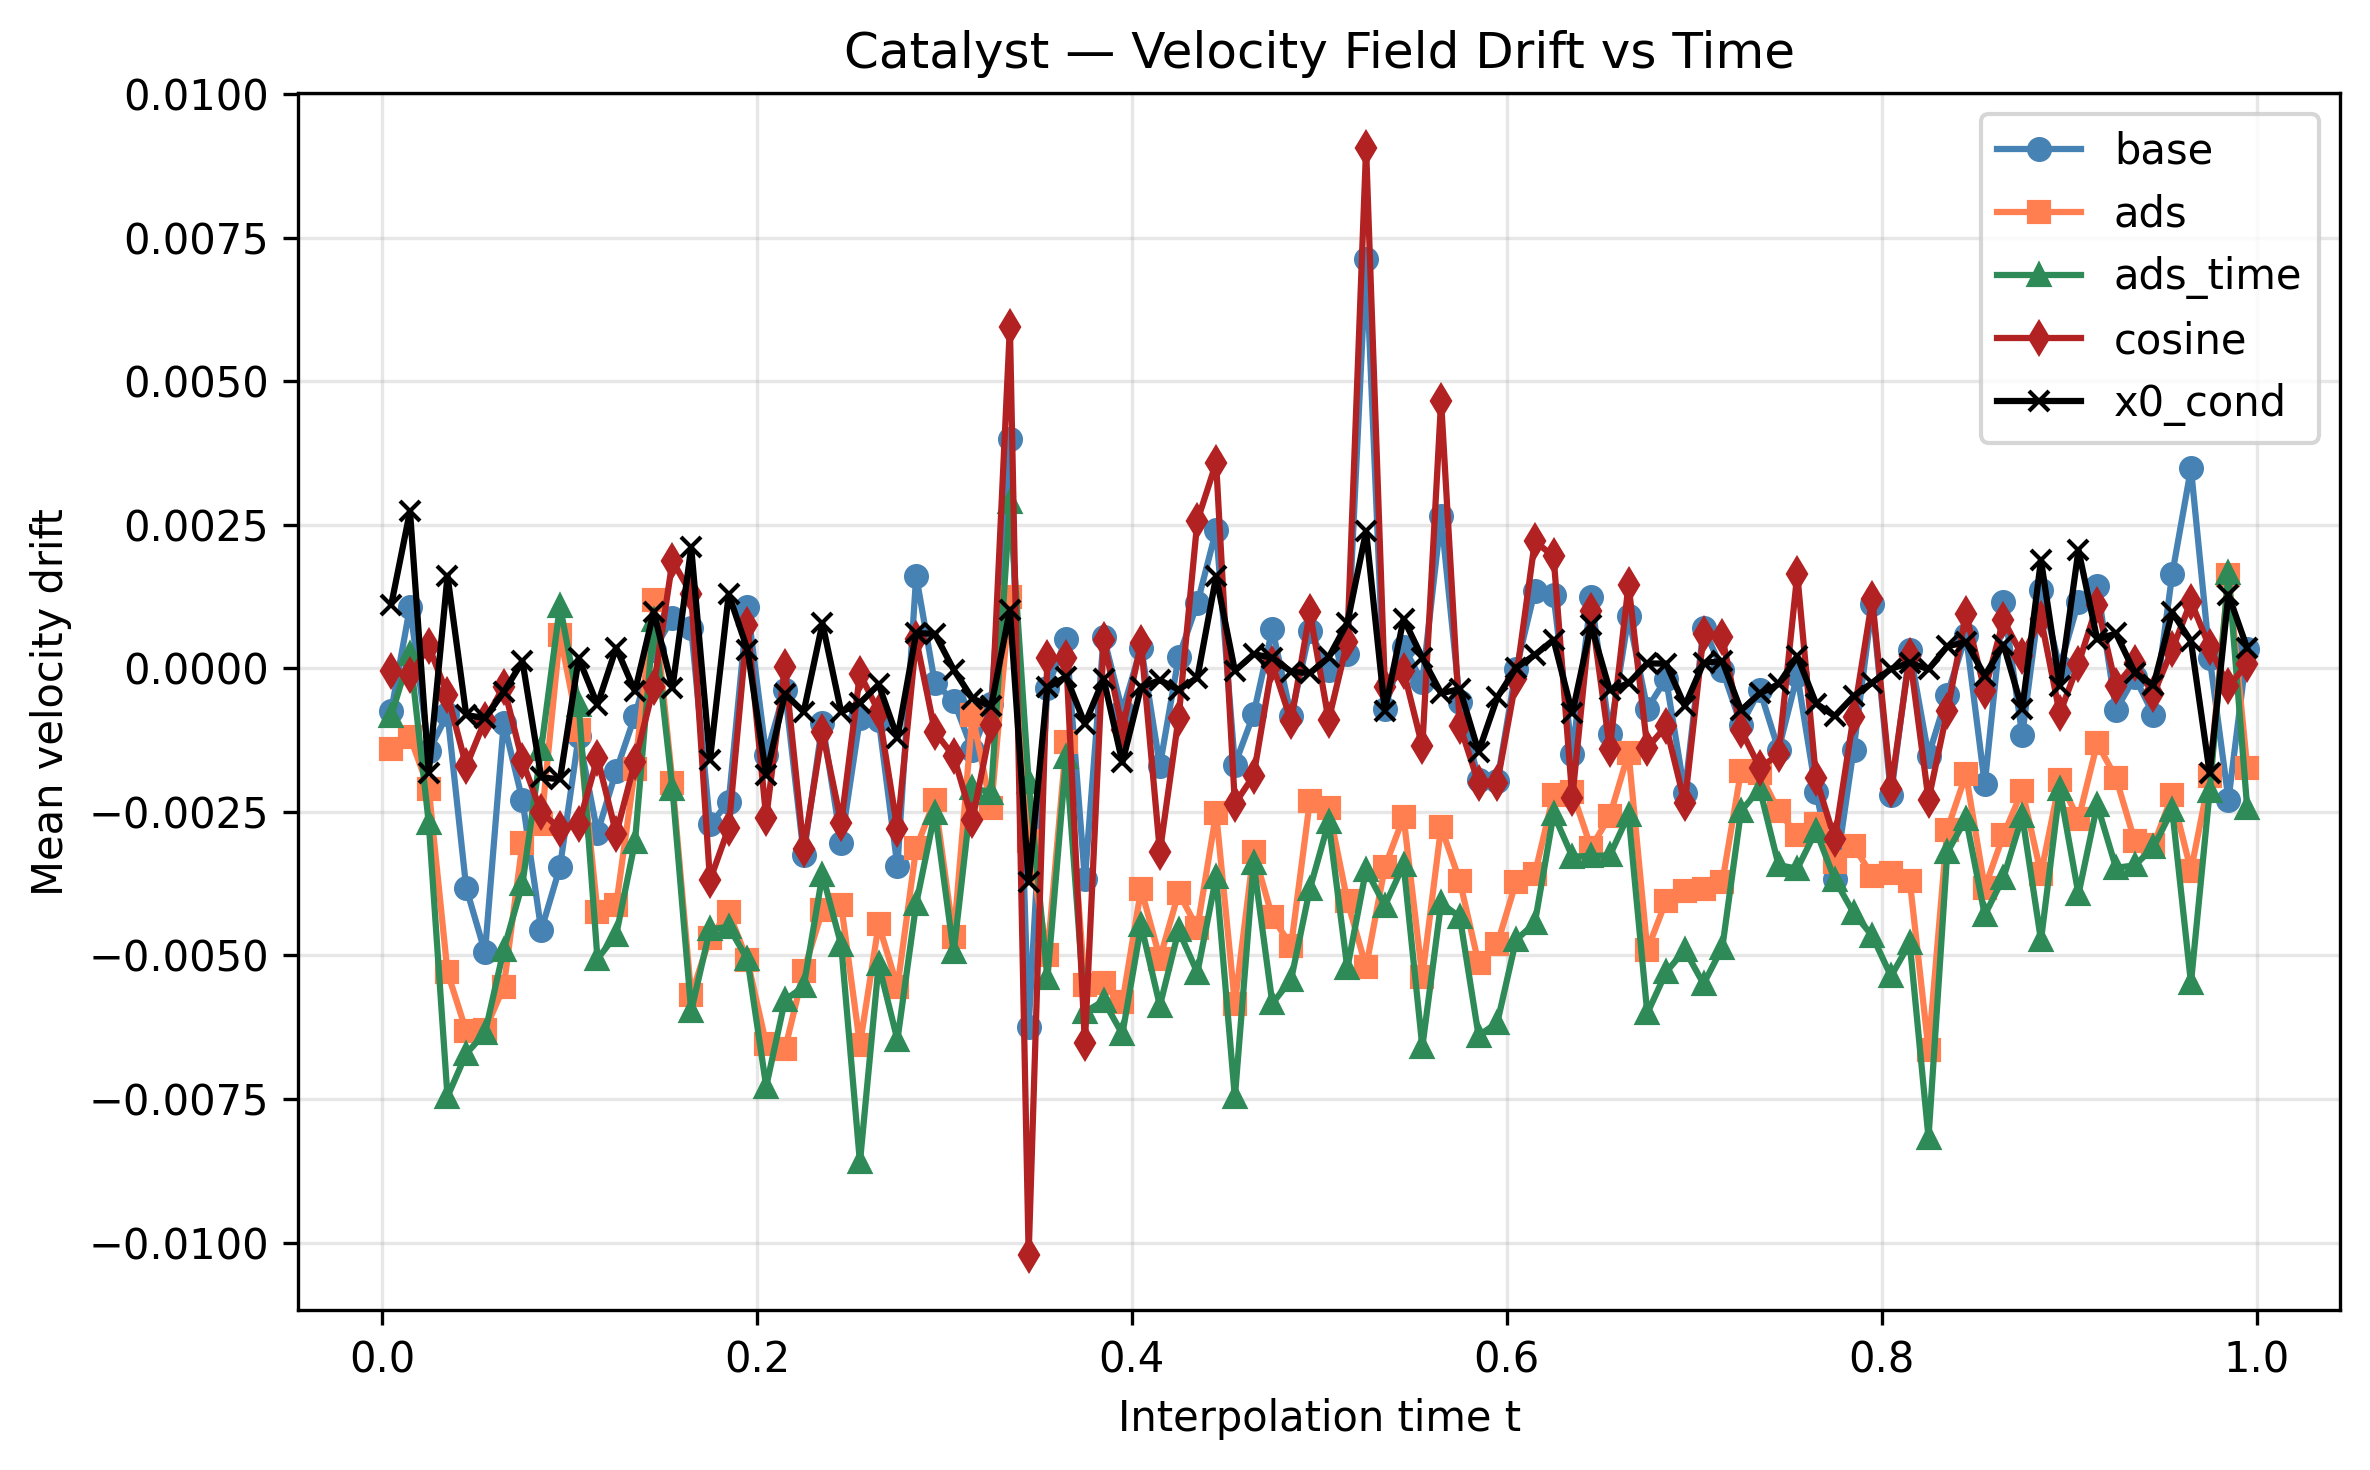

In [8]:
# Catalyst Drift — all datasets
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
for name in models:
    ax.plot(t_centers, results[name]['cat_drift'],
            f'{markers[name]}-', label=name, color=colors[name], markersize=5)
ax.set_xlabel('Interpolation time t')
ax.set_ylabel('Mean velocity drift')
ax.set_title('Catalyst — Velocity Field Drift vs Time')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


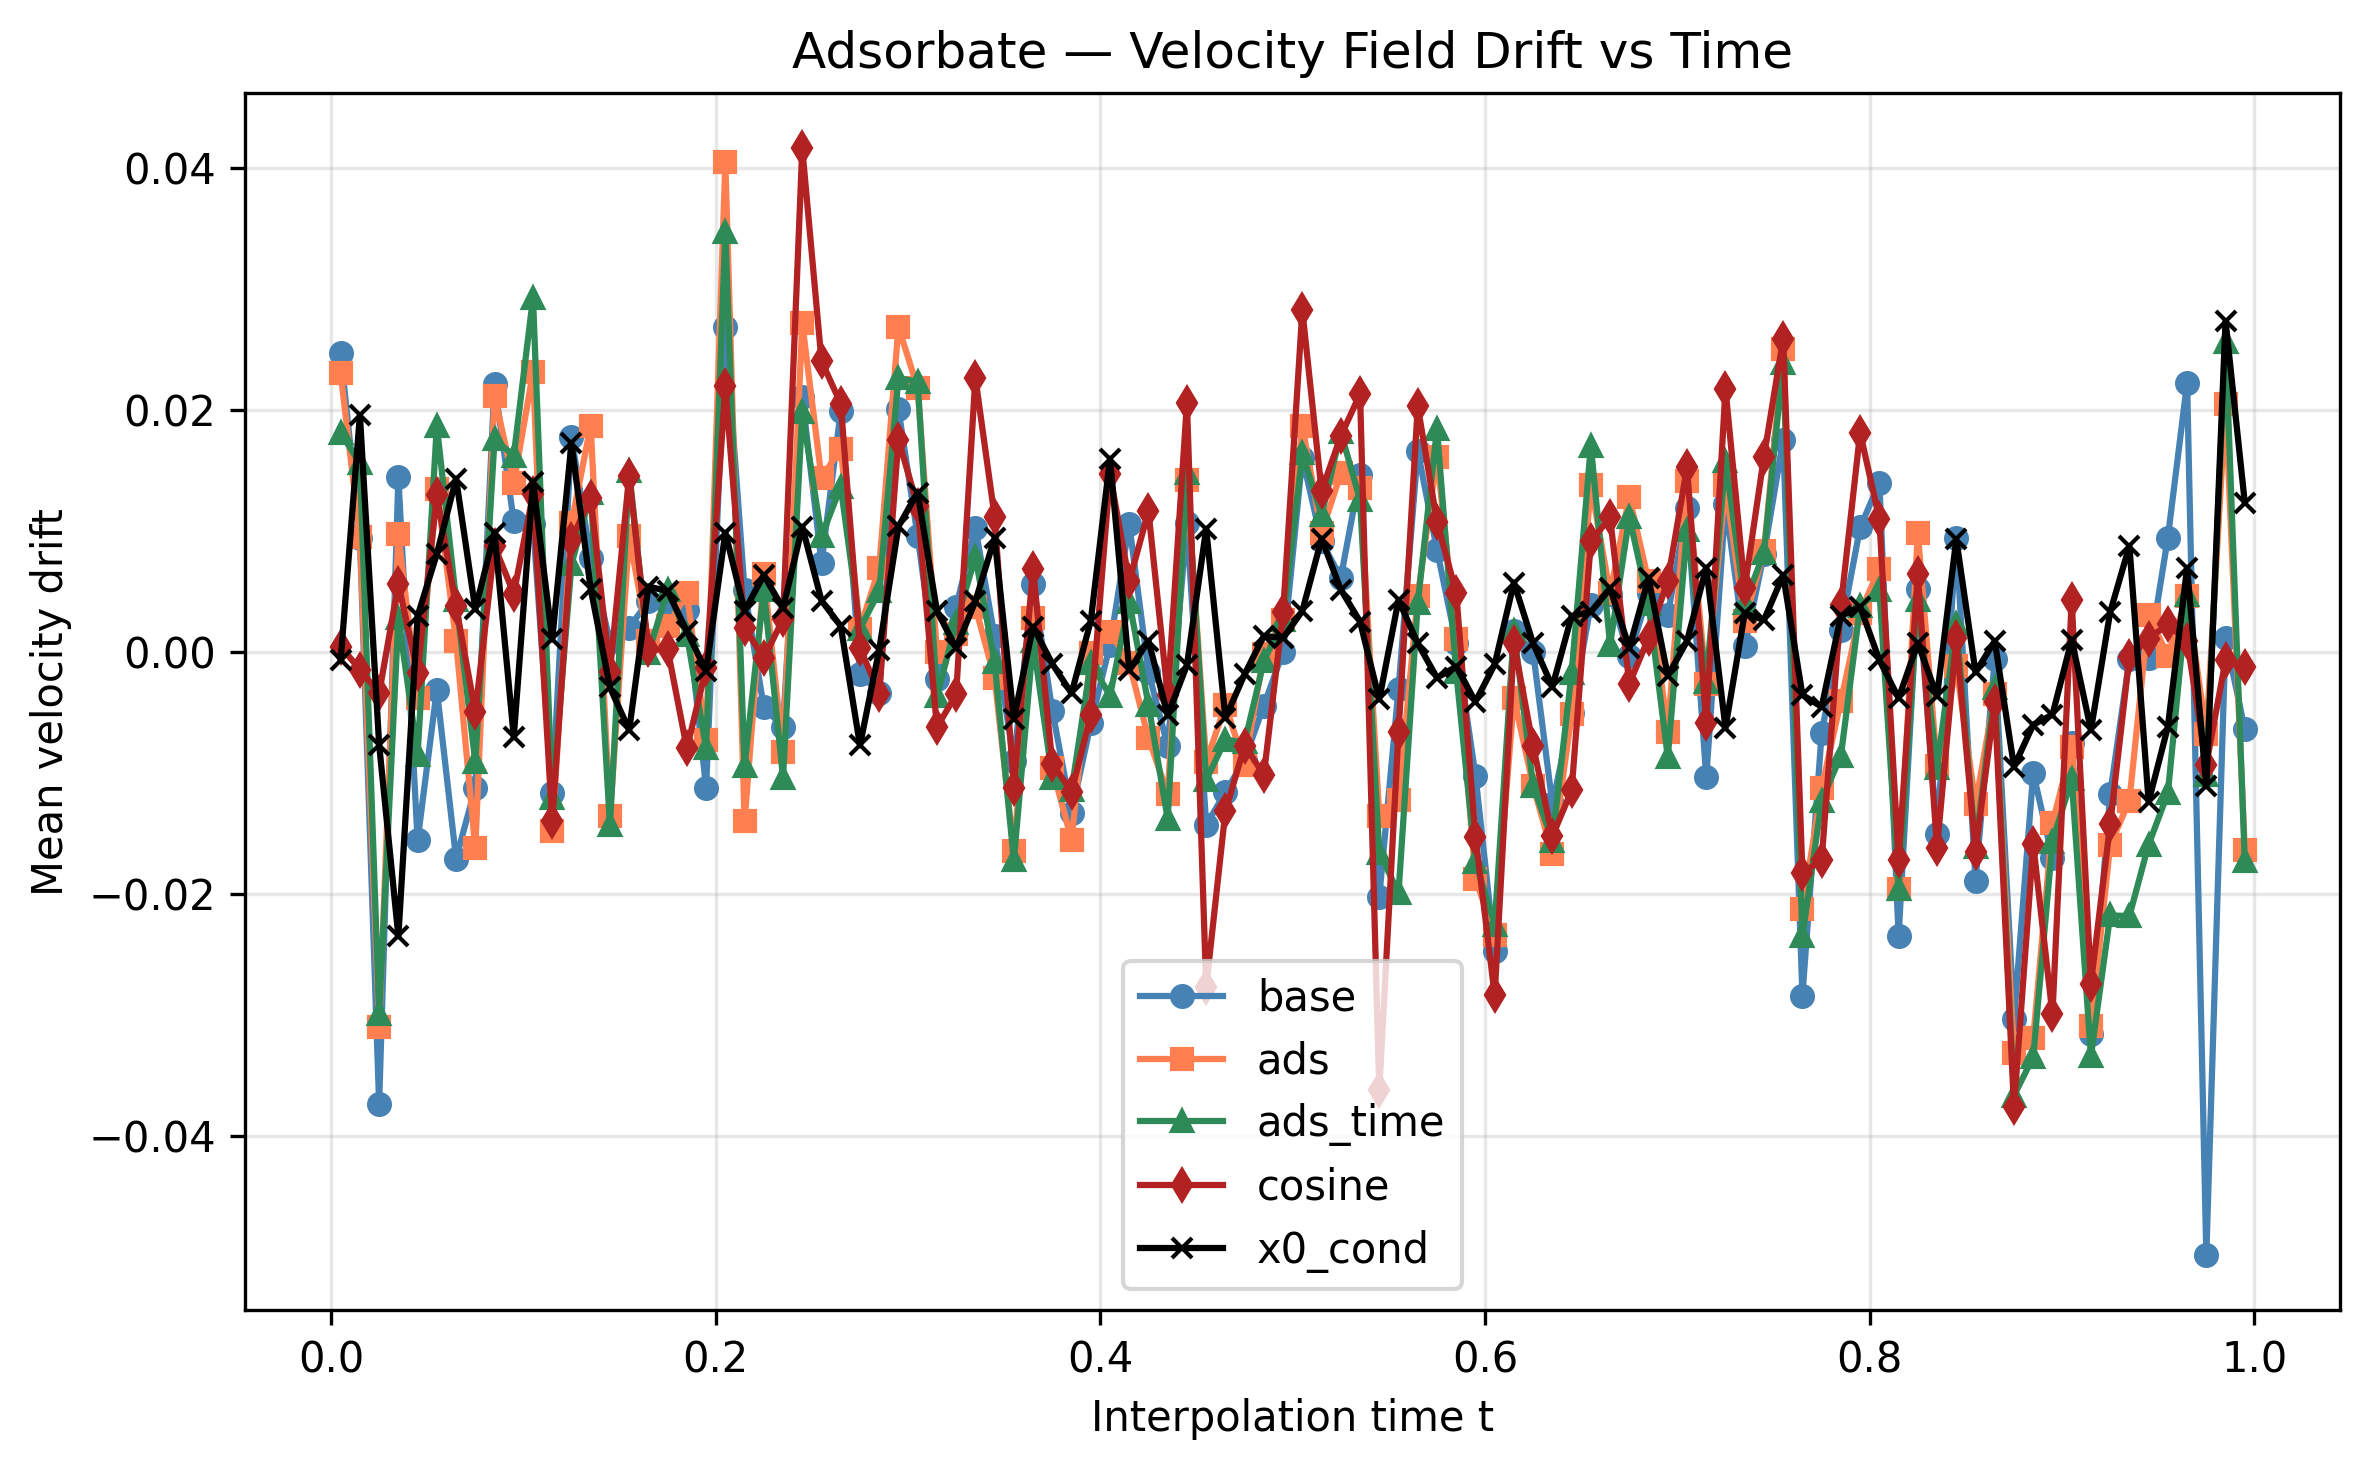

In [9]:
# Adsorbate Drift — all datasets
fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
for name in models:
    ax.plot(t_centers, results[name]['ads_drift'],
            f'{markers[name]}-', label=name, color=colors[name], markersize=5)
ax.set_xlabel('Interpolation time t')
ax.set_ylabel('Mean velocity drift')
ax.set_title('Adsorbate — Velocity Field Drift vs Time')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
